# MAPS Framework Tutorial
## Model Agnostic Post-hoc Synthetic Data Refinement

This tutorial demonstrates how to use MAPS to improve synthetic data quality while ensuring re-identifiability protection through a two-stage approach:
1. **Stage 1**: Remove identifiable synthetic samples (0-identifiability guarantee)
2. **Stage 2**: Enhance fidelity through importance weighting and resampling

The real data is split once into a training part and a test part. The generator and both MAPS stages see only the training part; the test part is held out for the utility evaluation.


In [1]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

# Add parent directory to path for imports
sys.path.append(os.path.abspath('..'))

# Set CUDA device if available
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
os.environ['CUDA_LAUNCH_BLOCKING'] = '0'

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification, make_blobs
from sklearn.preprocessing import StandardScaler
from scipy.stats import multivariate_normal

# Import MAPS components
from maps import FidelityClassifier, IdentifiabilityAnalyzer, SamplingEngine

# Set random seeds for reproducibility
np.random.seed(42)
plt.style.use('seaborn-v0_8')

print("MAPS Framework loaded successfully!")

MAPS Framework loaded successfully!


## Load the real data (from UCI dataset)

In [3]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition = fetch_ucirepo(id=544) 
  
# data (as pandas dataframes) 
X = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.features 
y = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.targets 
  
# concatenate dataframes
real_data = pd.concat([X, y], axis=1)

### Split the real data once into training and test parts

60% of the records, stratified by the class label, form the training part ($N$ records). Everything up to the evaluation uses the training part only.

In [4]:
from maps.data.splits import make_split

split = make_split(real_data, name='obesity', target='NObeyesdad',
                   train_frac=0.6, seed=0, stratify=True)
real_train, real_test = split.train, split.test
n_target = len(real_train)
print(f"Training part: {len(real_train)} records, test part: {len(real_test)} records")

Training part: 1266 records, test part: 845 records


## Generate the synthetic data (from Synthcity package)

In [5]:
%%capture
# %%capture hides the messages synthcity prints while loading its plugins
from synthcity.plugins.core.dataloader import GenericDataLoader
from synthcity.plugins import Plugins

In [6]:
# fit on the training part only; no train_size argument, because the loader would
# still hand the full frame to the generator
loader = GenericDataLoader(real_train)

In [7]:
%%capture
# %%capture hides the training progress bar
syn_model = Plugins().get("tvae", random_state=0)

syn_model.fit(loader)

### Generate 30N synthetic records to form the candidate pool

In [8]:
synthetic_data_pool = syn_model.generate(count=30 * n_target).dataframe()
print(f"Candidate pool: {len(synthetic_data_pool)} records")

Candidate pool: 37980 records


### Draw N records uniformly from the pool to form the raw baseline

In [9]:
rng = np.random.default_rng(seed=0)
random_indices = rng.choice(len(synthetic_data_pool), size=n_target, replace=False)
raw_synthetic_data = synthetic_data_pool.iloc[random_indices].reset_index(drop=True)

## Stage 1: remove all the identifiable synthetic samples (0-identifiability guaranteed)

In [10]:
identifiability_analyzer = IdentifiabilityAnalyzer()
identifiability_flags = identifiability_analyzer.fit(real_train, synthetic_data_pool)
# keep the records with identifiability_flags == 0
safe_indices = np.where(identifiability_flags == 0)[0]
synthetic_data_non_identifiable = synthetic_data_pool.iloc[safe_indices].reset_index(drop=True)
print(f"Stage 1: {len(synthetic_data_non_identifiable)}/{len(synthetic_data_pool)} records retained")

STARTING IDENTIFIABILITY ANALYSIS

1. PREPROCESSING DATA FOR IDENTIFIABILITY ANALYSIS
----------------------------------------
Starting data preprocessing for identifiability analysis...
Real data shape: (1266, 17)
Synthetic data shape: (37980, 17)
Merging datasets to create consistent encoders...
Numerical: 8, Categorical: 4, Binary: 5
  Encoded binary column 'Gender': 2 categories
  Encoded binary column 'family_history_with_overweight': 2 categories
  Encoded binary column 'FAVC': 2 categories
  Encoded categorical column 'CAEC': 4 categories
  Encoded binary column 'SMOKE': 2 categories
  Encoded binary column 'SCC': 2 categories
  Encoded categorical column 'CALC': 3 categories
  Encoded categorical column 'MTRANS': 5 categories
  Encoded categorical column 'NObeyesdad': 7 categories
Preprocessing complete. Shape: (1266, 17)

2. COMPUTING FEATURE WEIGHTS
----------------------------------------
Computed feature weights for 17 features

3. CALCULATING REAL SAMPLE DISTINCTNESS THRES

Calculated distinctness thresholds for 1266 real samples

4. COMPUTING IDENTIFIABILITY FLAGS FOR SYNTHETIC SAMPLES
----------------------------------------
  Computing distances between 1266 real and 37980 synthetic samples...


  Distance computation complete. Finding privacy violations...
  Privacy analysis complete:
  Synthetic samples marked as identifiable: 9992/37980
  Synthetic identifiability ratio: 0.2631
  Real samples with privacy violations: 431/1266
Identifiability analysis complete:
  Total synthetic samples: 37980
  Identifiable synthetic samples: 9992
  Synthetic identifiability ratio: 0.2631

IDENTIFIABILITY ANALYSIS COMPLETE!
  Overall real identifiability score: 0.3404
  (Overall score = ratio of real samples identifiable through synthetic data)
Stage 1: 27988/37980 records retained


## Stage 2: train a classifier on N real and N non-identifiable synthetic records

In [11]:
# N of the Stage 1 survivors train the classifier; they are removed from the pool,
# so the classifier never scores its own training data
synthetic_data_for_training = synthetic_data_non_identifiable.sample(n=n_target, random_state=42)
synthetic_data_for_resampling = synthetic_data_non_identifiable.drop(synthetic_data_for_training.index).reset_index(drop=True)

STARTING MAPS FIDELITY CLASSIFIER TRAINING
Real data for training: (1266, 17)
Synthetic data for training: (1266, 17)
Using embeddings for classifier: False

1. FITTING PREPROCESSOR ON FULL DATASETS
----------------------------------------
Starting data preprocessing for autoencoder...
Real data shape: (1266, 17)
Synthetic data shape: (1266, 17)
Identified 8 numerical, 4 categorical, 5 binary columns
Preprocessing complete. Shape: (1266, 32)

2. TRANSFORMING DATA
----------------------------------------


Processed real data shape: (1266, 32)
Processed synthetic training data shape: (1266, 32)
Note: Shapes should have same number of columns now

3. SKIPPING AUTOENCODER TRAINING (using processed data directly)
----------------------------------------

4. TRAINING CLASSIFIER FOR DENSITY RATIO ESTIMATION
----------------------------------------
Using processed data for classifier training: (1266, 32)
Training mlp classifier with sigmoid calibration


Test Accuracy: 0.7909
Test ROC AUC: 0.8556
Odds ratio (kappa): 1.0000


<Figure size 1000x700 with 0 Axes>

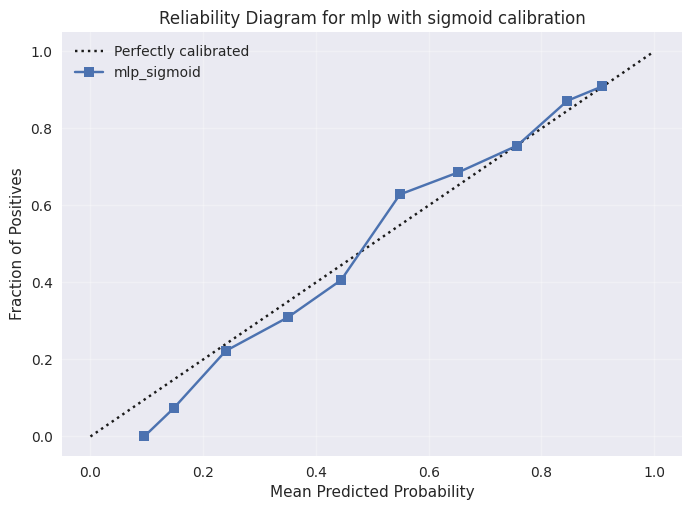


FIDELITY CLASSIFIER TRAINING COMPLETE!
Note: Use estimate_importance_weights(synthetic_data) with separate
synthetic data to avoid data leakage.
Estimating importance weights for 26722 synthetic samples
Using embeddings: False
Using processed data for importance weight estimation: (26722, 32)


In [12]:
fidelity_classifier = FidelityClassifier(classifier_type='mlp', calibration_method='sigmoid')
accuracy, roc_auc = fidelity_classifier.fit(real_train, synthetic_data_for_training,
                                            mlp_hidden_layer_sizes=(120, 60),
                                            classifier_test_size=0.2,
                                            use_embedding=False,
                                            )
importance_weights, probs = fidelity_classifier.estimate_importance_weights(synthetic_data_for_resampling, use_embedding=False)

### Sampling-Importance-Resampling to get N refined synthetic records

In [13]:
sampling_engine = SamplingEngine()
refined_data, weights, flags, indices, stats = sampling_engine.sample(
    synthetic_data=synthetic_data_for_resampling,
    importance_weights=importance_weights,
    n_samples=n_target,
    method='weighted',            # Options: 'top_k', 'weighted', 'reverse_weighted', 'reverse_top_k'
    weight_processing='flatten',  # Options: 'raw', 'flatten', 'clipped'
    alpha=1,                      # Tempering exponent for flatten: weights ** alpha
    replacement=True,             # SIR draws with replacement
)
print(f"Refined {stats['selected_samples']} samples ({stats['n_unique_samples']} unique)")
refined_synthetic_data = refined_data.copy()

Running Standard SIR sampler to select 1266 samples using weighted method
Weight processing: flatten
  Alpha parameter: 1
  Original weights - Min: 0.094313, Max: 10.011699, Std: 1.341855, Mean: 0.868904
  Processed weights - Min: 0.094313, Max: 10.011699, Std: 1.341855, Mean: 0.868904
Standard SIR sampling complete. Selected 1266 samples (1186 unique, duplicate rate 0.063, ESS 7895 = 29.5% of pool, replacement=True).
Weight statistics - Min: 0.0972, Max: 10.0037, Mean: 2.8605
Refined 1266 samples (1186 unique)


## Evaluation

Fidelity and the identifiability score are measured against the training part, which is the reference the generator and MAPS were fitted to. Utility is measured on the held-out test part.

### Identifiability score of the raw and refined data

In [14]:
def identifiability_score(real, synthetic):
    # fraction of synthetic records lying closer to a real record than that record's nearest real neighbour
    return float(np.mean(IdentifiabilityAnalyzer(verbose=False).fit(real, synthetic)))

print(f"Identifiability score, raw:     {identifiability_score(real_train, raw_synthetic_data):.4f}")
print(f"Identifiability score, refined: {identifiability_score(real_train, refined_synthetic_data):.4f}")

Identifiability score, raw:     0.2694
Identifiability score, refined: 0.0000


### Visualize marginal distributions

In [15]:
from maps.utils.ResultsVisualization import visualize_distributions

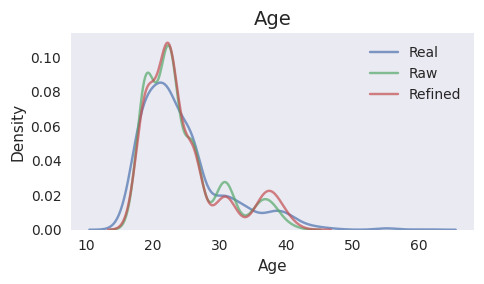

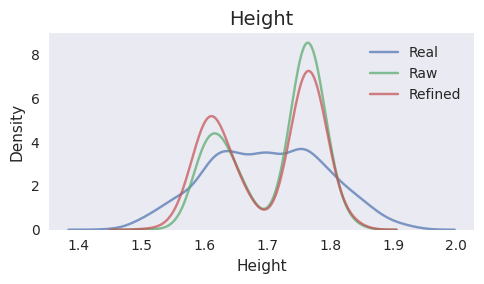

In [16]:
col = ['Age','Height']
fig = visualize_distributions(
    real_data=real_train,
    baseline_data=raw_synthetic_data,
    filtered_data=refined_synthetic_data,
    columns=col,
    figsize=(5, 3),
    separate_figures=True
)

### Quantify the distribution similarity

In [17]:
from maps.utils.DistSimTest import evaluate_distribution_similarity

In [18]:
results_with_discretization = evaluate_distribution_similarity(
    real_train, raw_synthetic_data, refined_synthetic_data,
    discretize_numerical=True,
    mmd_kernel='rbf'
)

DISTRIBUTION SIMILARITY EVALUATION
Identified 8 numerical and 9 categorical columns
Numerical columns: ['TUE', 'Height', 'FCVC', 'NCP', 'Weight']...
Categorical columns: ['CALC', 'MTRANS', 'SCC', 'family_history_with_overweight', 'CAEC']...
Discretization enabled: Categorical metrics will include discretized numerical columns

Computing Jensen-Shannon Distance (Marginal)...
  Jensen-Shannon Distance (Marginal): Raw=0.185763, Refined=0.173177 ✓

Computing Jensen-Shannon Distance (Joint Categorical)...
  Jensen-Shannon Distance (Joint Categorical): Raw=0.546176, Refined=0.476524 ✓

Computing Inverse KL Divergence (Marginal)...


  Inverse KL Divergence (Marginal): Raw=0.679512, Refined=0.708014 ✓

Computing Chi-squared Test p-value (Marginal)...
  Chi-squared Test p-value (Marginal): Raw=0.428215, Refined=0.519719 ✓

Computing Total Variation Distance (Marginal)...


  Total Variation Distance (Marginal): Raw=0.186507, Refined=0.178143 ✓

Computing Kolmogorov-Smirnov Test (Marginal)...
  Kolmogorov-Smirnov Test (Marginal): Raw=0.820004, Refined=0.824151 ✓

Computing Wasserstein Distance (Joint)...


  Wasserstein Distance (Joint): Raw=0.046949, Refined=0.041274 ✓

Computing Maximum Mean Discrepancy (Joint, rbf)...


  Maximum Mean Discrepancy (Joint, rbf): Raw=0.004039, Refined=0.004165 ✗

Computing Hellinger Distance (Marginal)...
  Hellinger Distance (Marginal): Raw=0.199119, Refined=0.184583 ✓

SUMMARY RESULTS
                                     Metric   Data Type Distribution Type Raw Synthetic Refined Synthetic Improvement   Interpretation
         Jensen-Shannon Distance (Marginal)         All          Marginal      0.185763          0.173177           ✓  Lower is better
Jensen-Shannon Distance (Joint Categorical) Categorical             Joint      0.546176          0.476524           ✓  Lower is better
           Inverse KL Divergence (Marginal)         All          Marginal      0.679512          0.708014           ✓ Higher is better
        Chi-squared Test p-value (Marginal)         All          Marginal      0.428215          0.519719           ✓ Higher is better
        Total Variation Distance (Marginal)         All          Marginal      0.186507          0.178143           ✓  Lower

### Compare the correlation structure

ASYMMETRIC MIXED CORRELATION ANALYSIS
Properly handling correlation ratio asymmetry with lower triangle display
Configuration: use_mixed=True, method=spearman
Categorical columns (9): ['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE', 'SCC', 'CALC', 'MTRANS', 'NObeyesdad']
Numerical columns (8): ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']

Matrix Structure (Lower Triangle Only):
• Categorical-Categorical: Cramer's V (symmetric, red box)
• Categorical→Numerical: Correlation Ratio η² (asymmetric, green box)
• Numerical-Numerical: Correlation coefficient (symmetric, blue box)



ASYMMETRIC CORRELATION STRUCTURE ANALYSIS
---------------------------------------------
Categorical-Categorical (Cramer's V): range [0.0, 0.551196593662468], mean = 0.165
Categorical→Numerical (η²): range [1.1261092414385582e-05, 0.8487601220672387], mean = 0.050
Numerical-Numerical (spearman): range [-0.30557482663457725, 0.4522743418866727], mean = 0.073

SIMILARITY METRICS (Lower Triangle Only)
---------------------------------------------
Metric                    Raw          Refined      Improvement 
-----------------------------------------------------------------
frobenius_normalized      0.1068       0.0588             +45.0%
mae_overall               0.0614       0.0349             +43.1%
weighted_mae              0.0705       0.0422             +40.1%
-----------------------------------------------------------------

DETAILED BREAKDOWN BY CORRELATION TYPE:
---------------------------------------------
Num-Num : 0.0780 → 0.0596 (+23.6%)
Cat-Cat : 0.0958 → 0.0486 (+49.3%)
Cat-

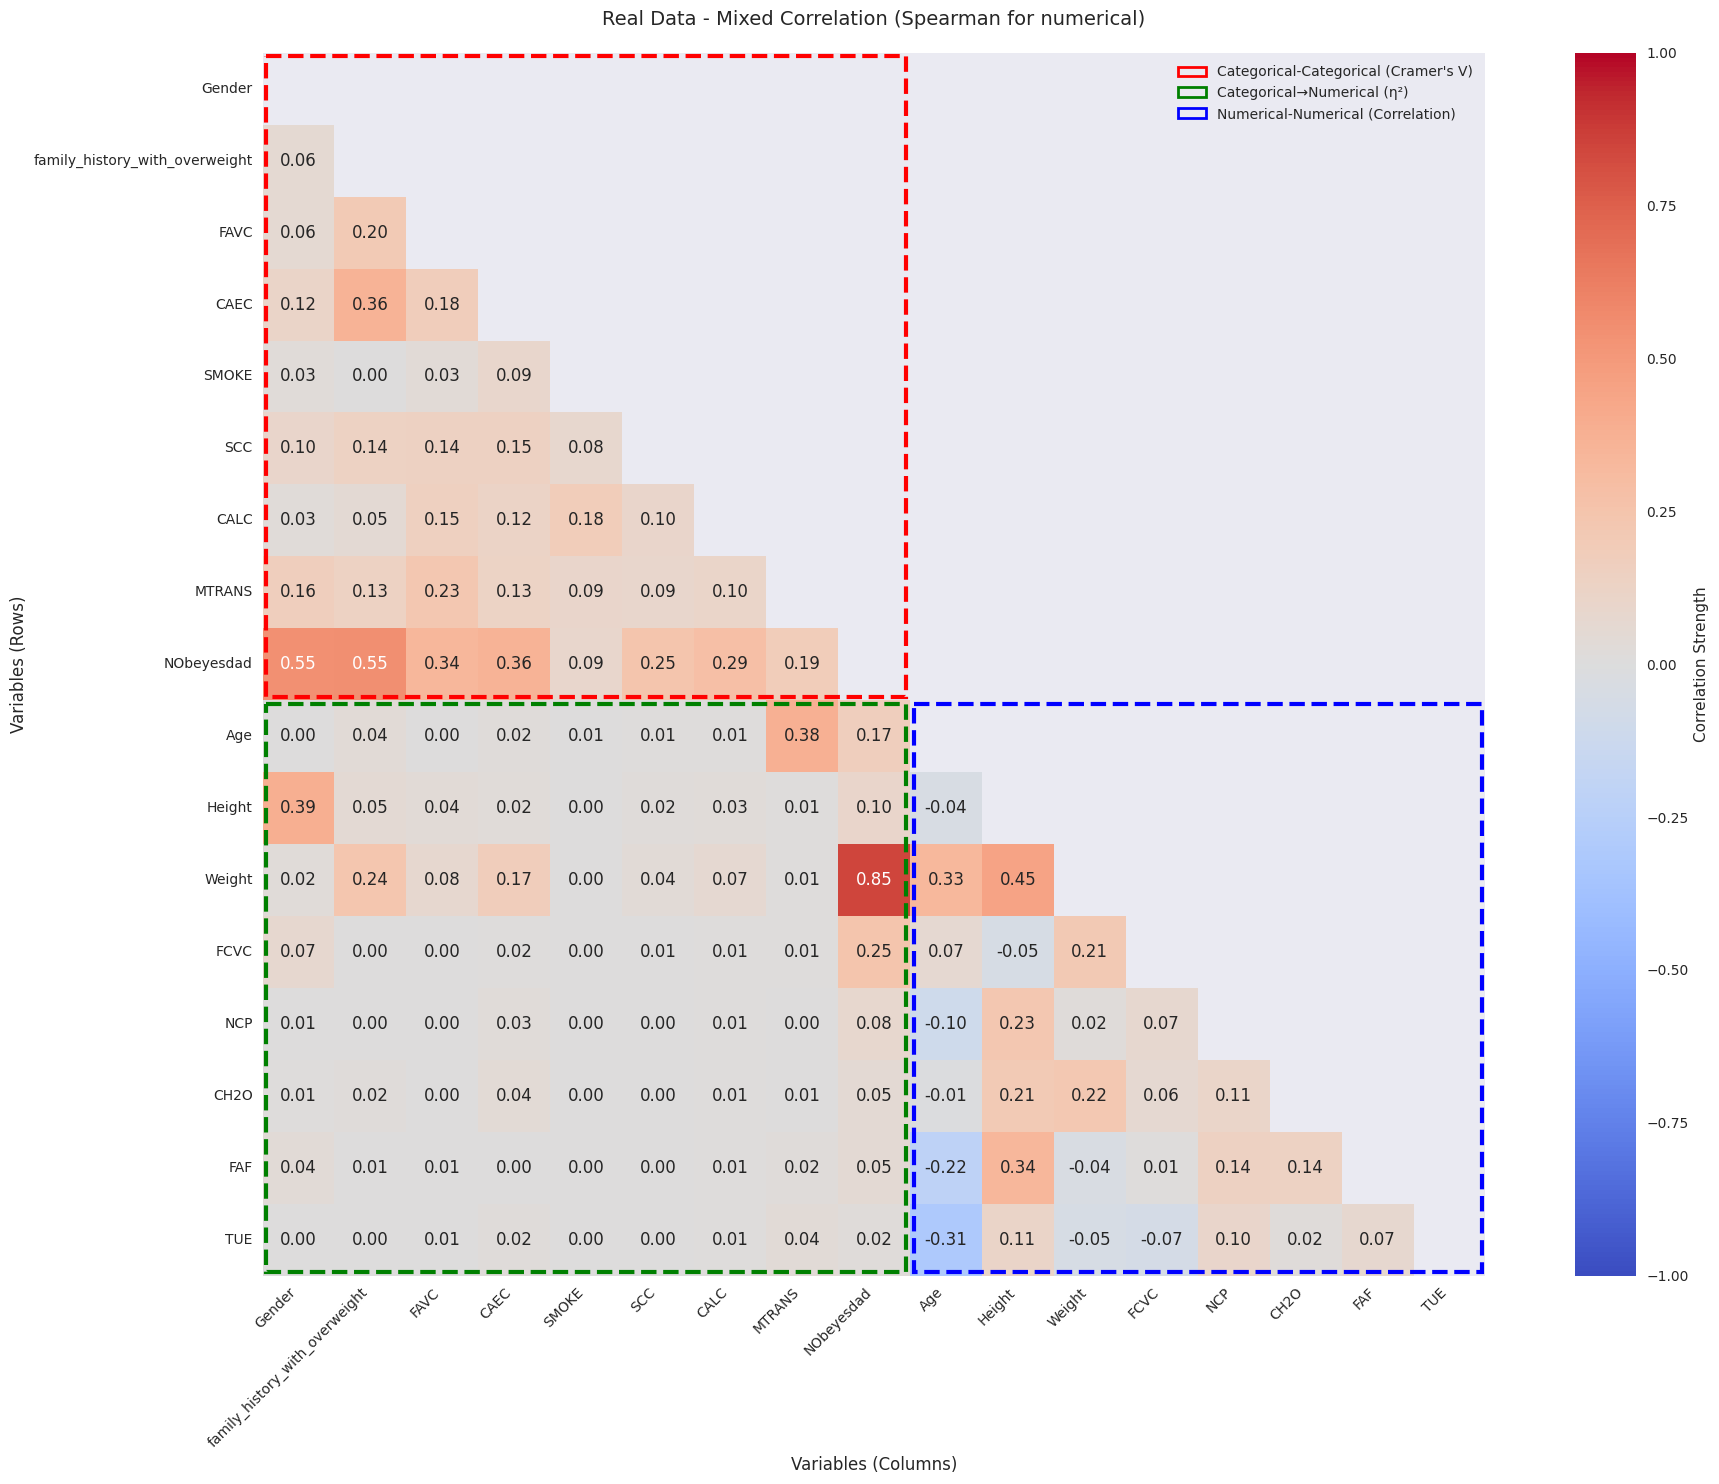

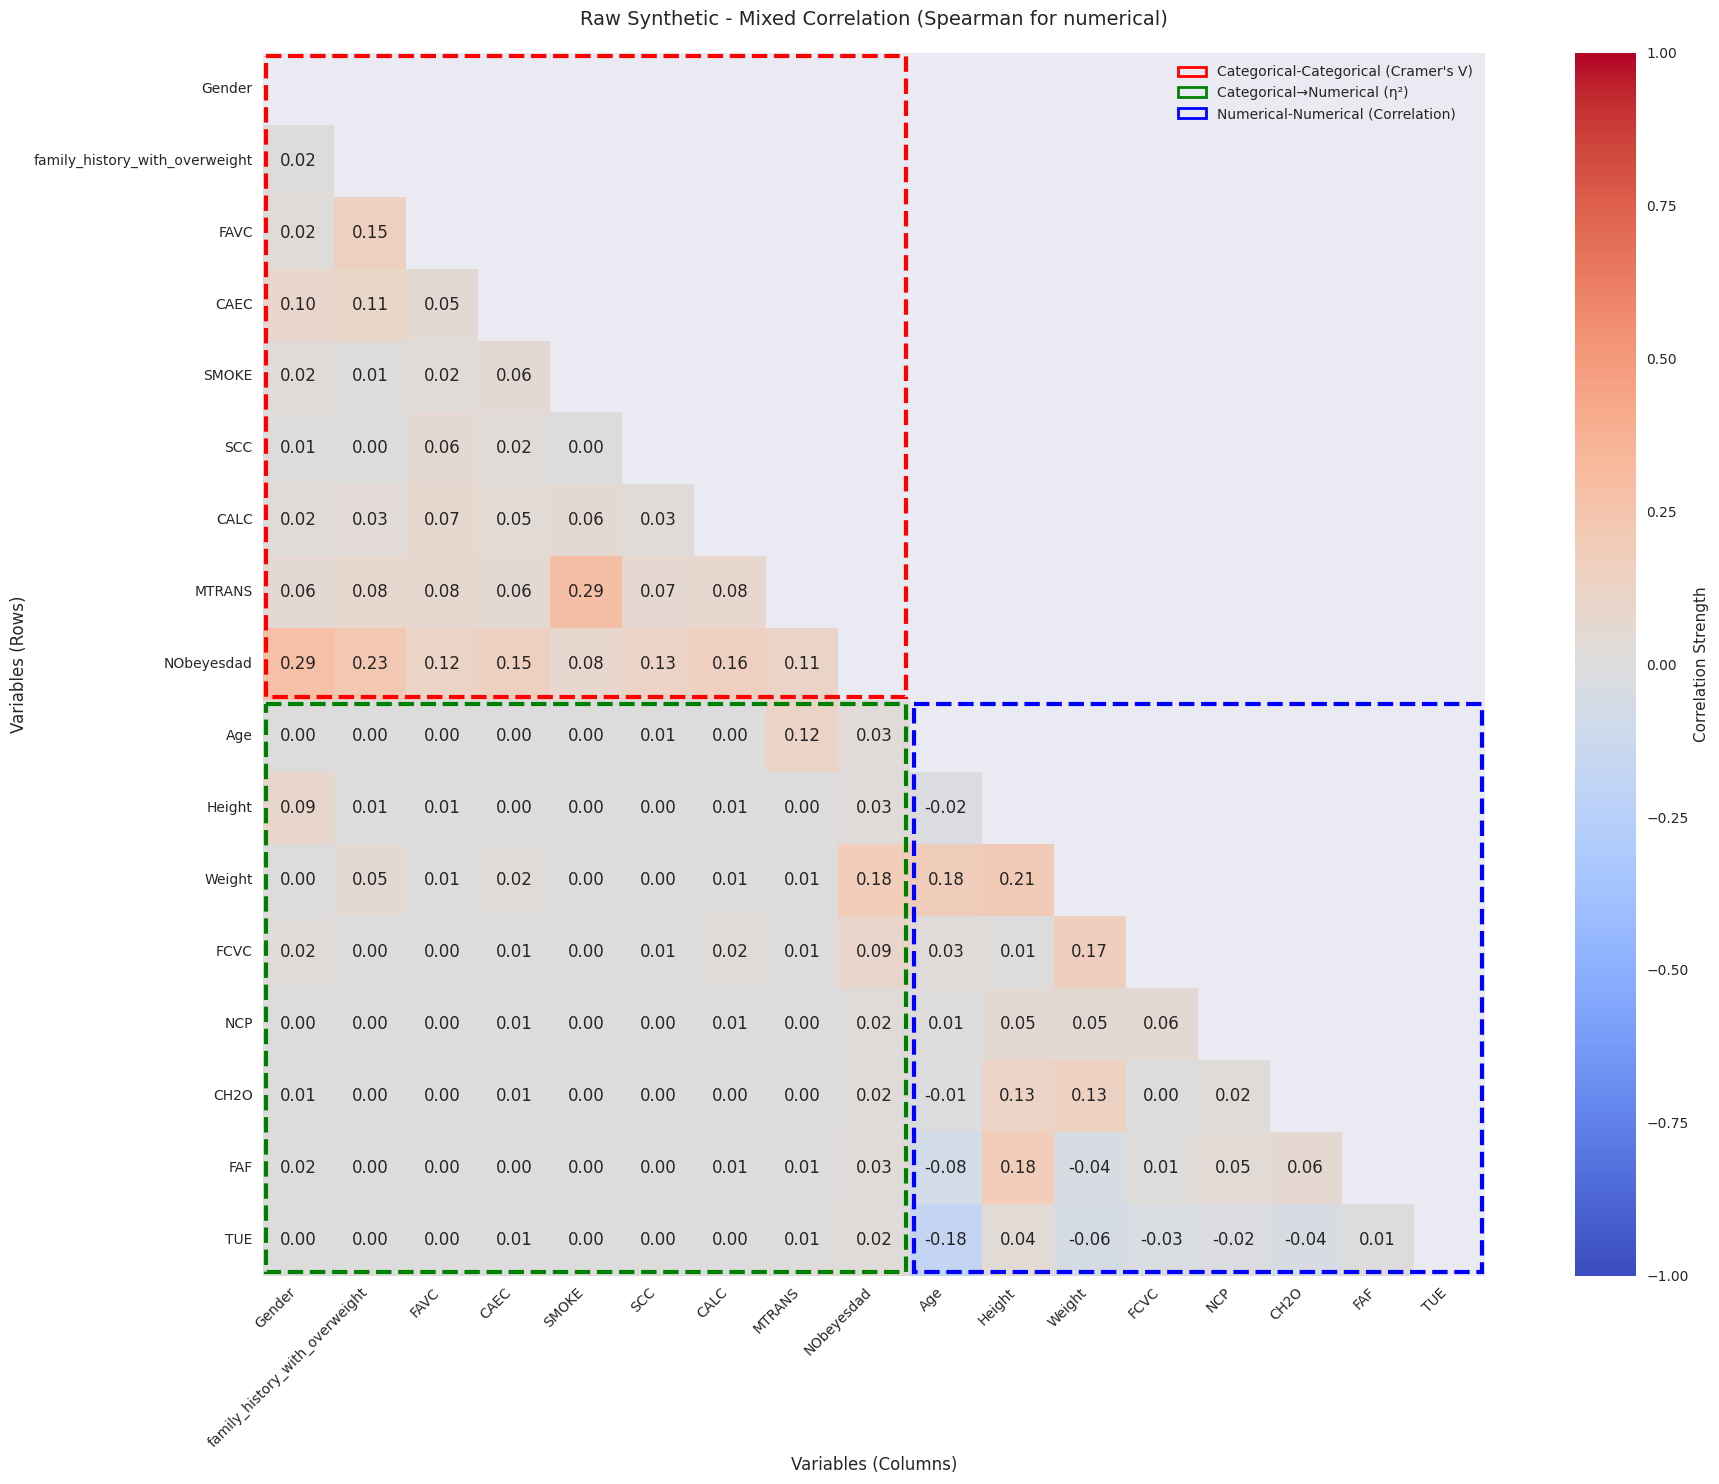

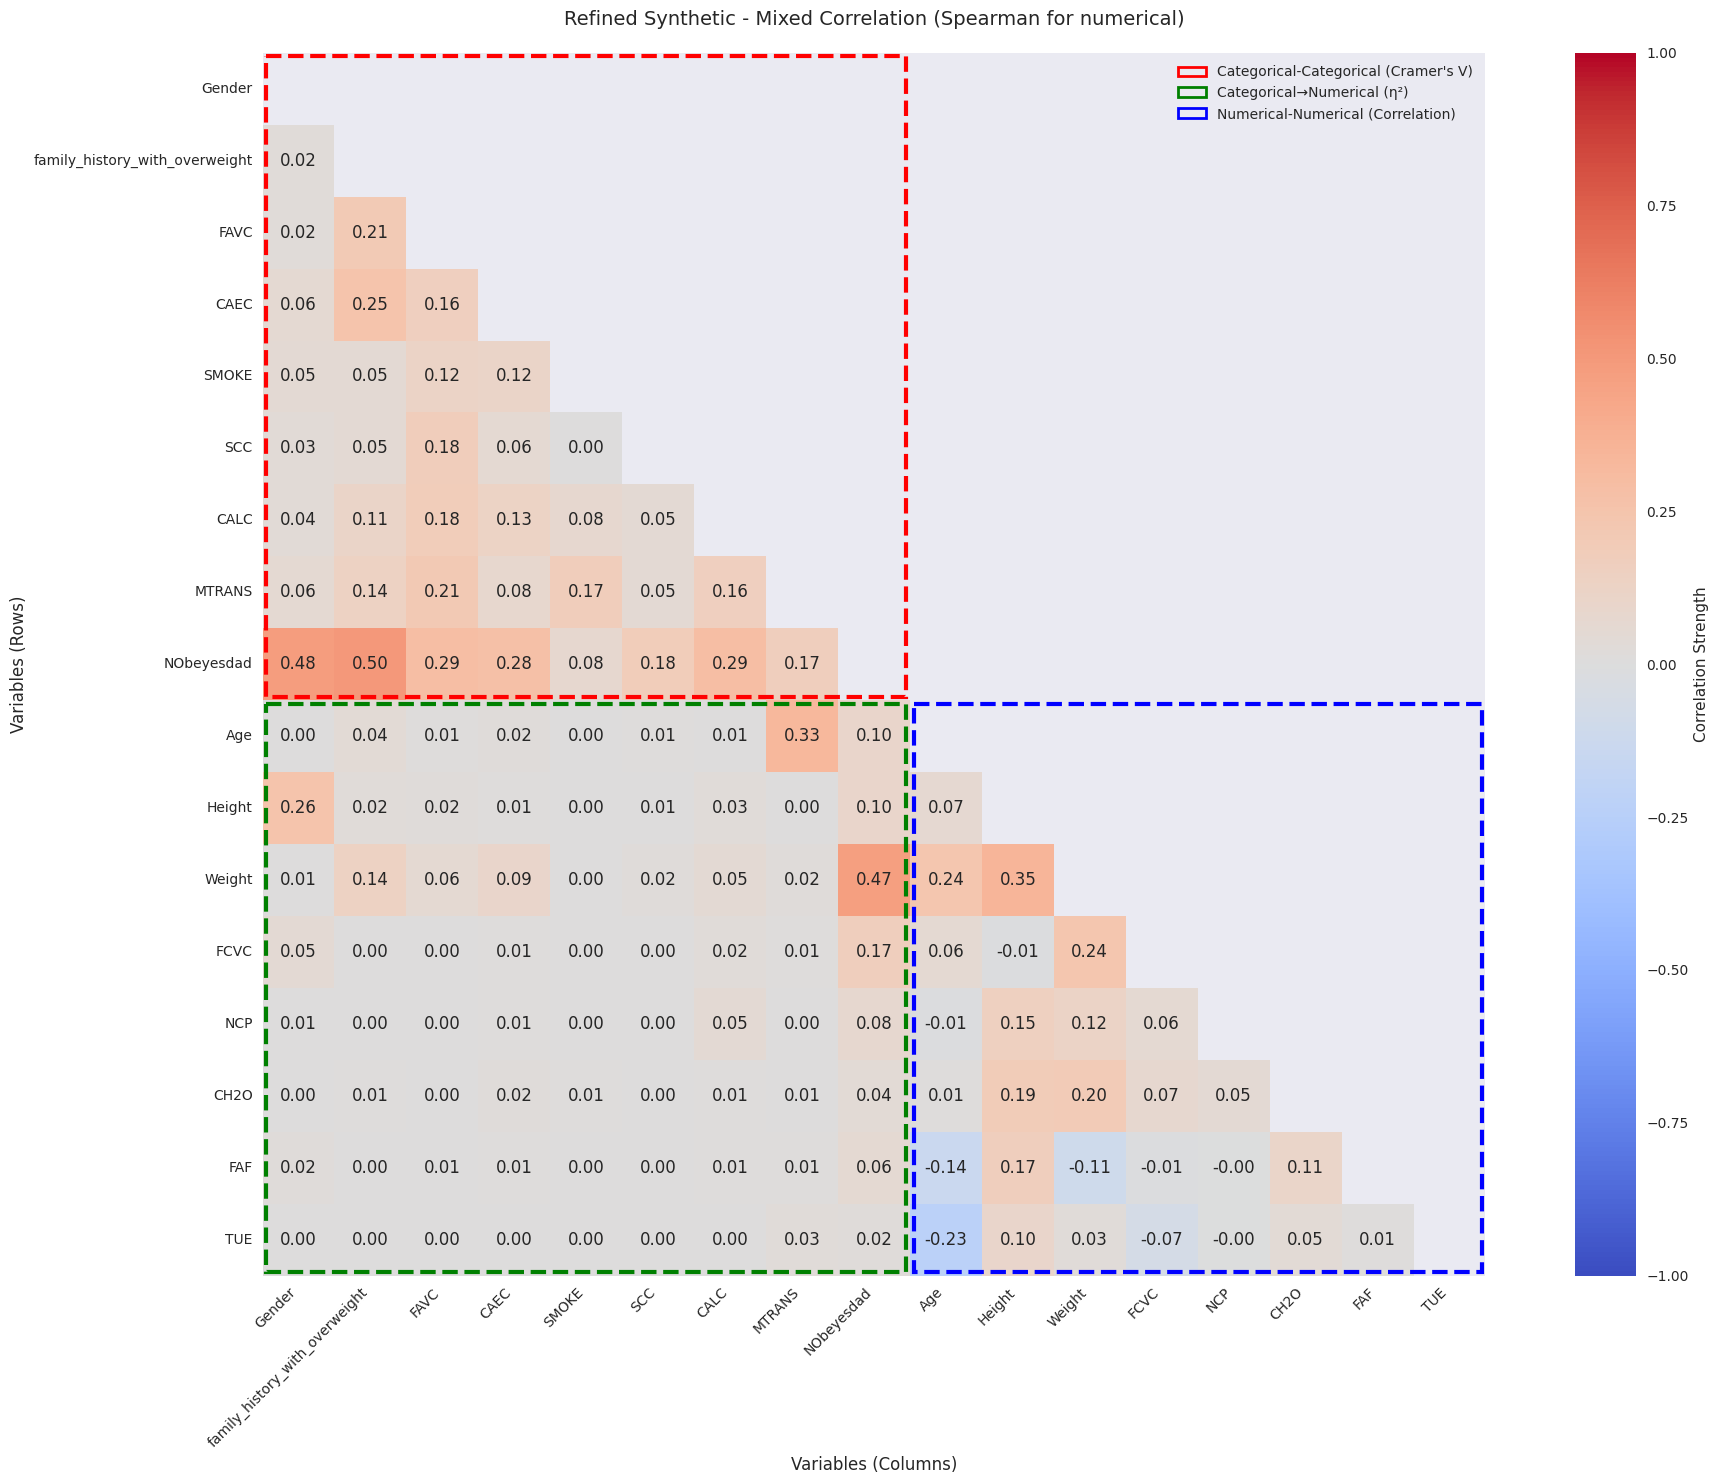

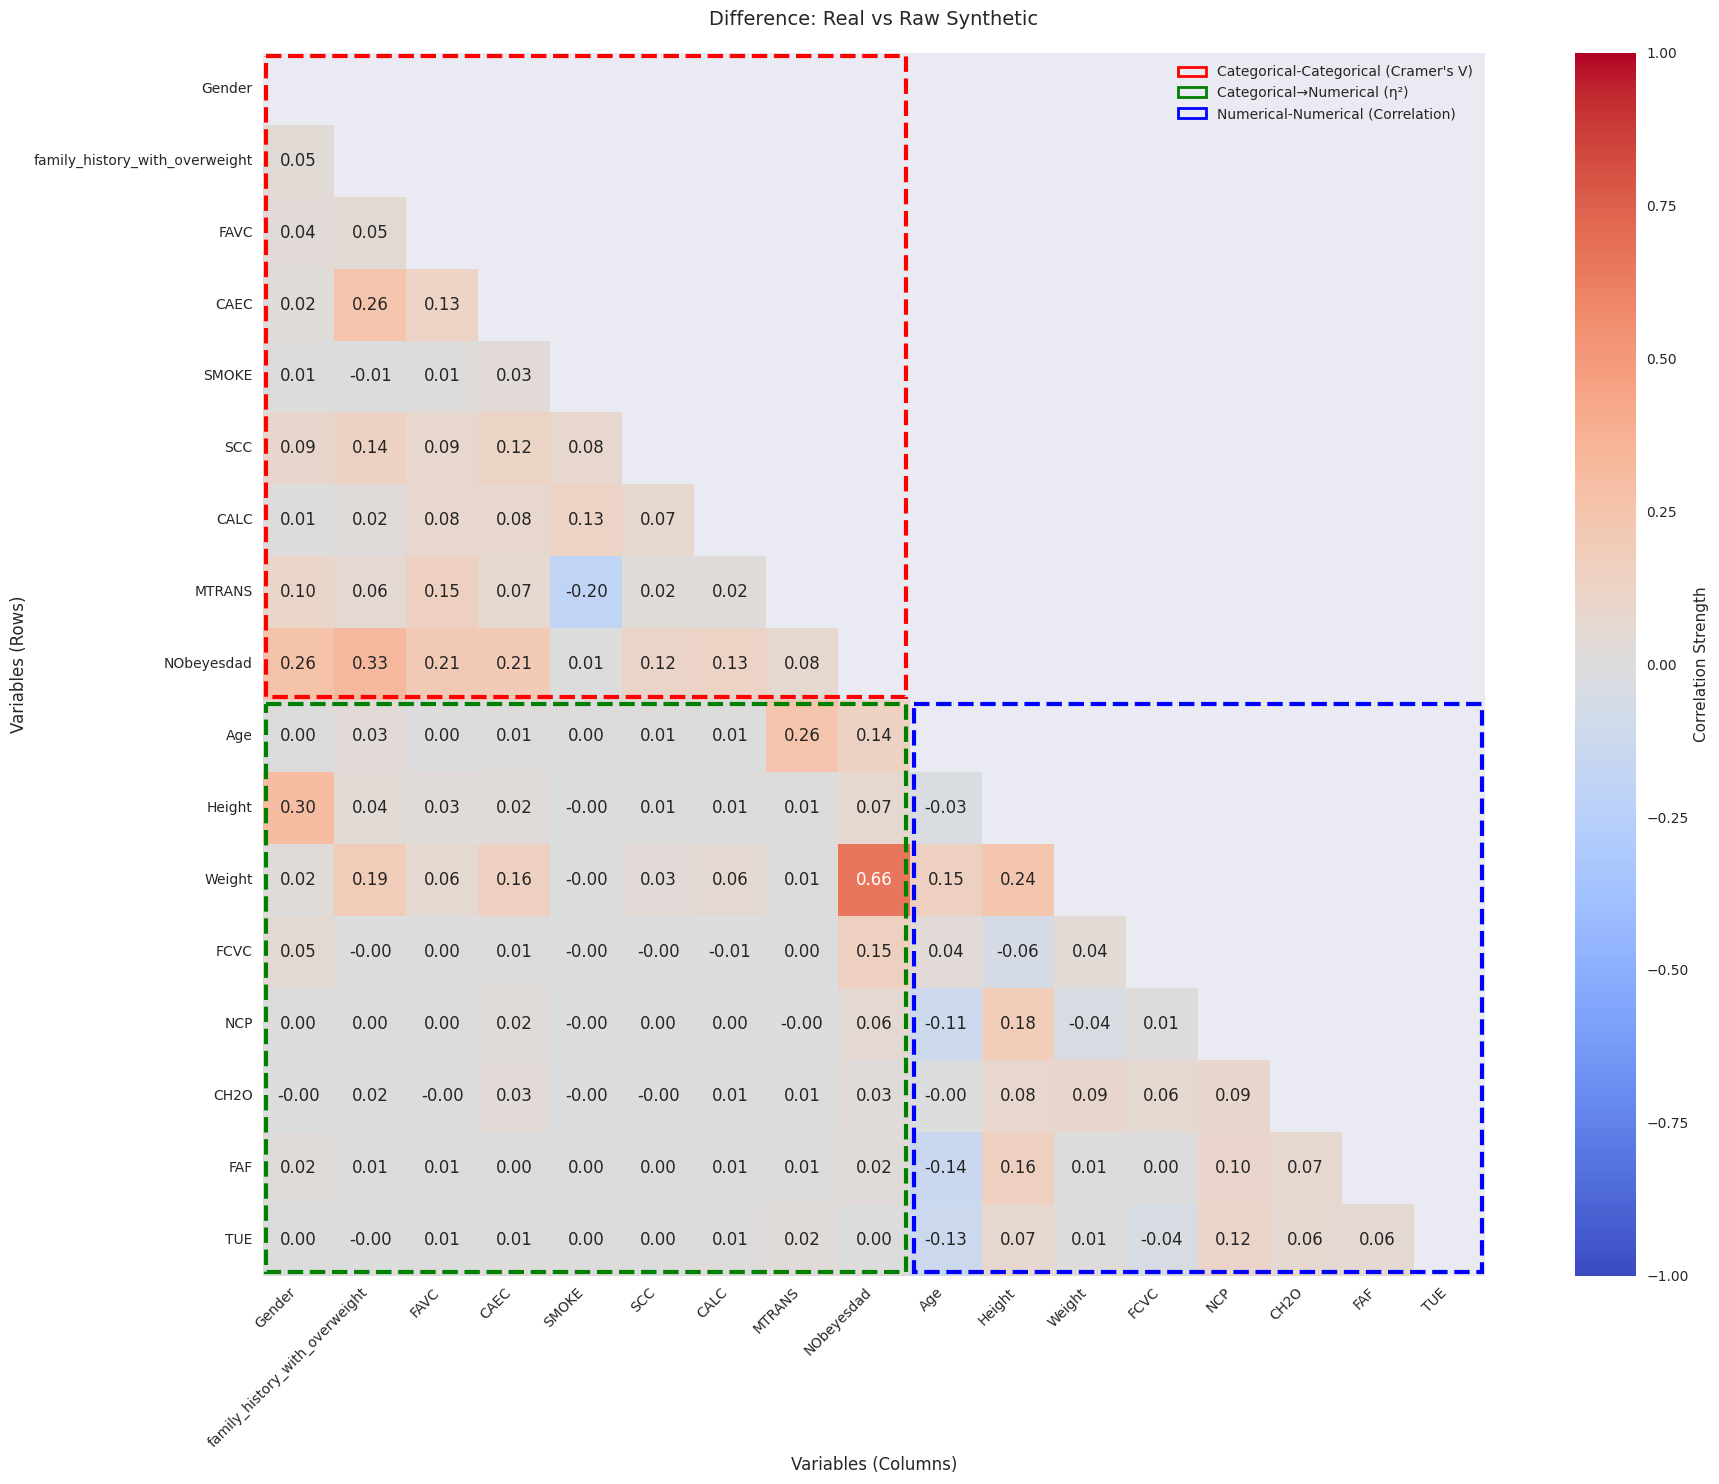

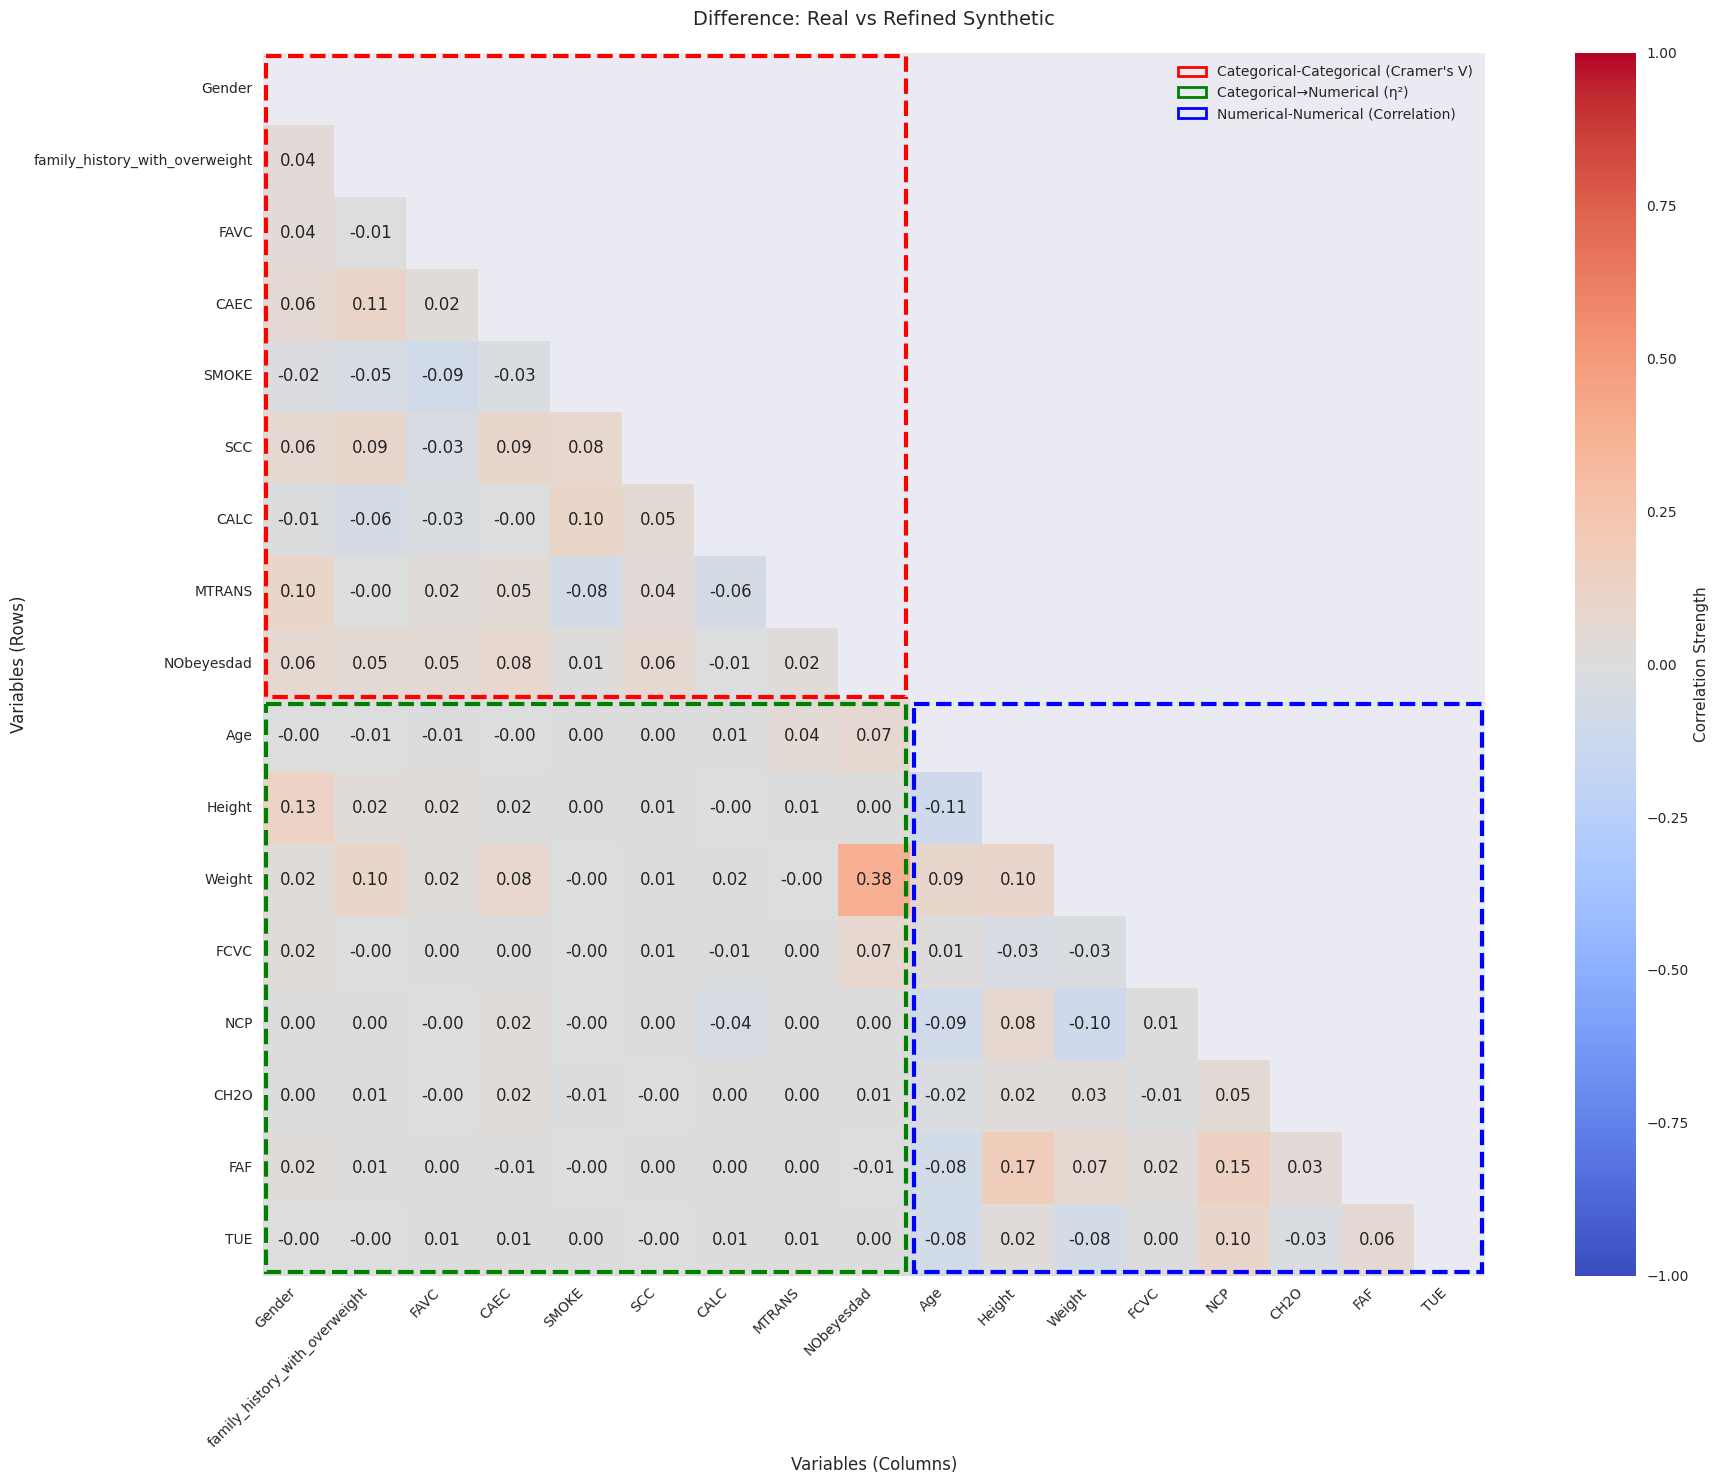

Asymmetric analysis complete! Lower triangle display resolves correlation ratio asymmetry.
Consensus improvement: 42.7% +/- 2.0%


In [19]:
from maps.utils.CorrAnalyzer import mixed_correlation_analysis

results = mixed_correlation_analysis(
    real_data=real_train,
    raw_synthetic_data=raw_synthetic_data,
    refined_synthetic_data=refined_synthetic_data,
    use_mixed=True,
    detailed_analysis=True,
    method='spearman',
    figsize = (20,15)
)

consensus_improvement = results['similarity_scores']['consensus_improvement']
consensus_std = results['similarity_scores']['consensus_std']

print(f"Consensus improvement: {consensus_improvement:.1f}% +/- {consensus_std:.1f}%")

## Utility test

A classifier is trained on the raw or the refined synthetic data and tested on the held-out test part of the real data.

In [20]:
from maps.core.utility import run_utility_evaluation,plot_evaluation_results,print_summary_table,plot_feature_importance_comparison

ENHANCED UTILITY EVALUATION: TRAIN ON SYNTHETIC, TEST ON REAL
Cross-Validation: All Metrics (Accuracy, F1-Macro, ROC-AUC)
Feature Importance Analysis Included
Synthetic datasets subsampled to match real training size

Analyzing target classes across datasets...
All unique classes found: ['Insufficient_Weight', 'Normal_Weight', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III', 'Overweight_Level_I', 'Overweight_Level_II']
Target encoder classes: ['Insufficient_Weight' 'Normal_Weight' 'Obesity_Type_I' 'Obesity_Type_II'
 'Obesity_Type_III' 'Overweight_Level_I' 'Overweight_Level_II']

Splitting real data for proper evaluation...
Test size: 20%, CV validation size: 20% of remaining data
Using STRICT data-isolation protocol (externally supplied D_train / D_test)
Real train set: 1012 samples
Real CV validation set: 254 samples
Real test set: 845 samples

Sampling synthetic datasets to match real training size: 1012 samples
Raw synthetic train set: 1012 samples
Refined synthetic train se

    Fold 1: Accuracy=0.5882, F1=0.5587, ROC-AUC=0.8714


    Fold 2: Accuracy=0.7255, F1=0.7124, ROC-AUC=0.9436


    Fold 3: Accuracy=0.5882, F1=0.5614, ROC-AUC=0.9049


    Fold 4: Accuracy=0.7059, F1=0.6837, ROC-AUC=0.9382


    Fold 5: Accuracy=0.6800, F1=0.6568, ROC-AUC=0.9083


... (4 outputs left out)

    Fold 4: Accuracy=0.6863, F1=0.6740, ROC-AUC=0.9480


    Fold 5: Accuracy=0.7400, F1=0.7234, ROC-AUC=0.9639


CV Accuracy: 0.7519 ± 0.0537
CV F1-Macro: 0.7371 ± 0.0584
CV ROC-AUC: 0.9519 ± 0.0117
Test Accuracy: 0.7254
Test F1-Macro: 0.7122
Test ROC-AUC: 0.9376

SCENARIO 3: Train on Real (Train Split), Test on Real (Test Split)
             CV: Train on Real, Validate on Real
             [REAL-DATA BASELINE]

Evaluating Real (Train) → Real (Test):
  Training data shape: (1012, 16)
  Test data shape: (845, 16)
  Performing standard CV: Train and validate on same data type


CV Accuracy: 0.9160 ± 0.0180
CV F1-Macro: 0.9142 ± 0.0185
CV ROC-AUC: 0.9930 ± 0.0020
Test Accuracy: 0.9444
Test F1-Macro: 0.9428
Test ROC-AUC: 0.9961

FEATURE IMPORTANCE ANALYSIS


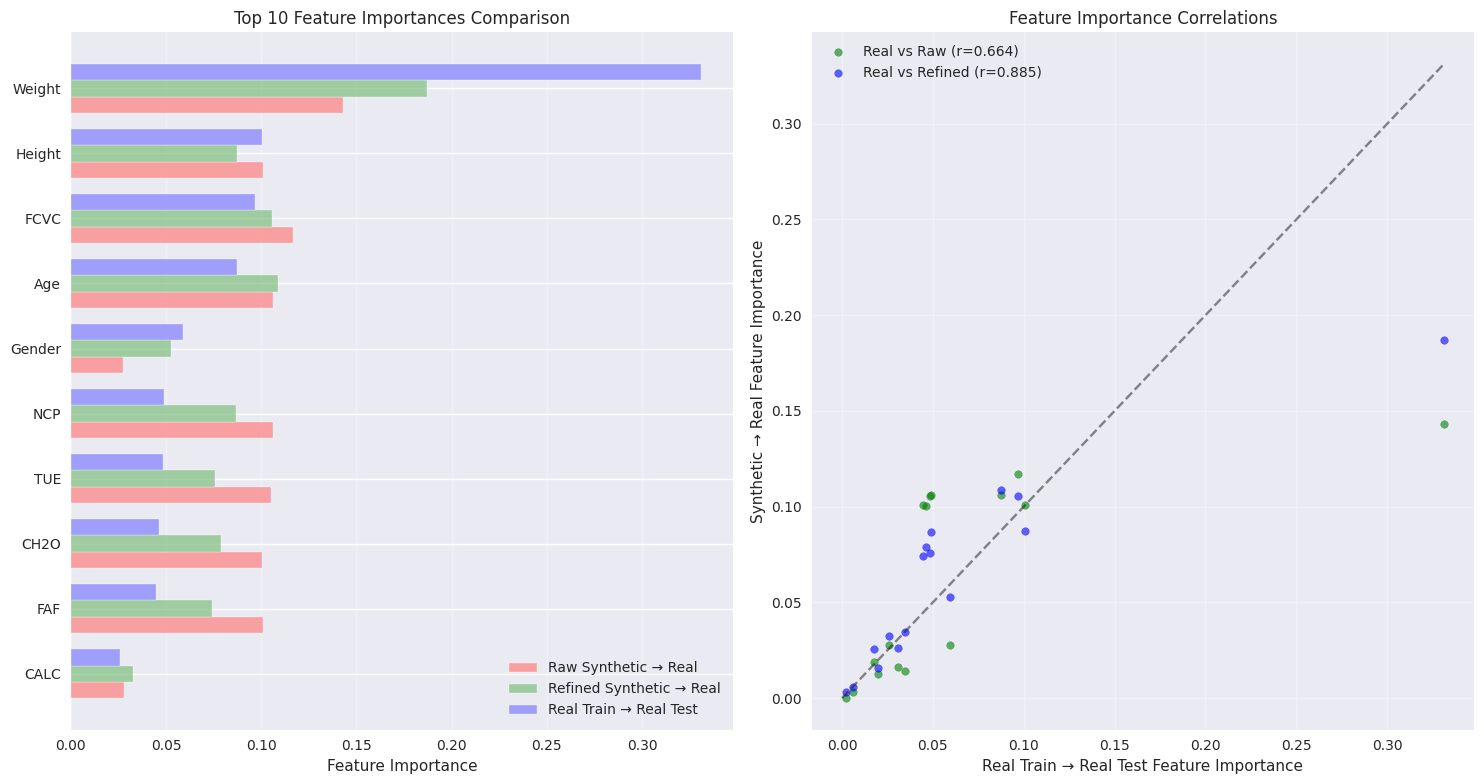


Feature Importance Correlation Analysis:
Real vs Raw Synthetic: 0.6639
Real vs Refined Synthetic: 0.8851

Top 5 Features by Importance:
Raw Synthetic → Real:
  1. Weight: 0.1430
  2. FCVC: 0.1168
  3. Age: 0.1063
  4. NCP: 0.1060
  5. TUE: 0.1053

Refined Synthetic → Real:
  1. Weight: 0.1869
  2. Age: 0.1089
  3. FCVC: 0.1056
  4. Height: 0.0872
  5. NCP: 0.0868

Real Train → Real Test:
  1. Weight: 0.3312
  2. Height: 0.1005
  3. FCVC: 0.0967
  4. Age: 0.0875
  5. Gender: 0.0592



In [21]:
results = run_utility_evaluation(real_train, raw_synthetic_data, refined_synthetic_data,
                                 target_column='NObeyesdad', random_state=42,
                                 real_train_data=real_train, real_test_data=real_test)

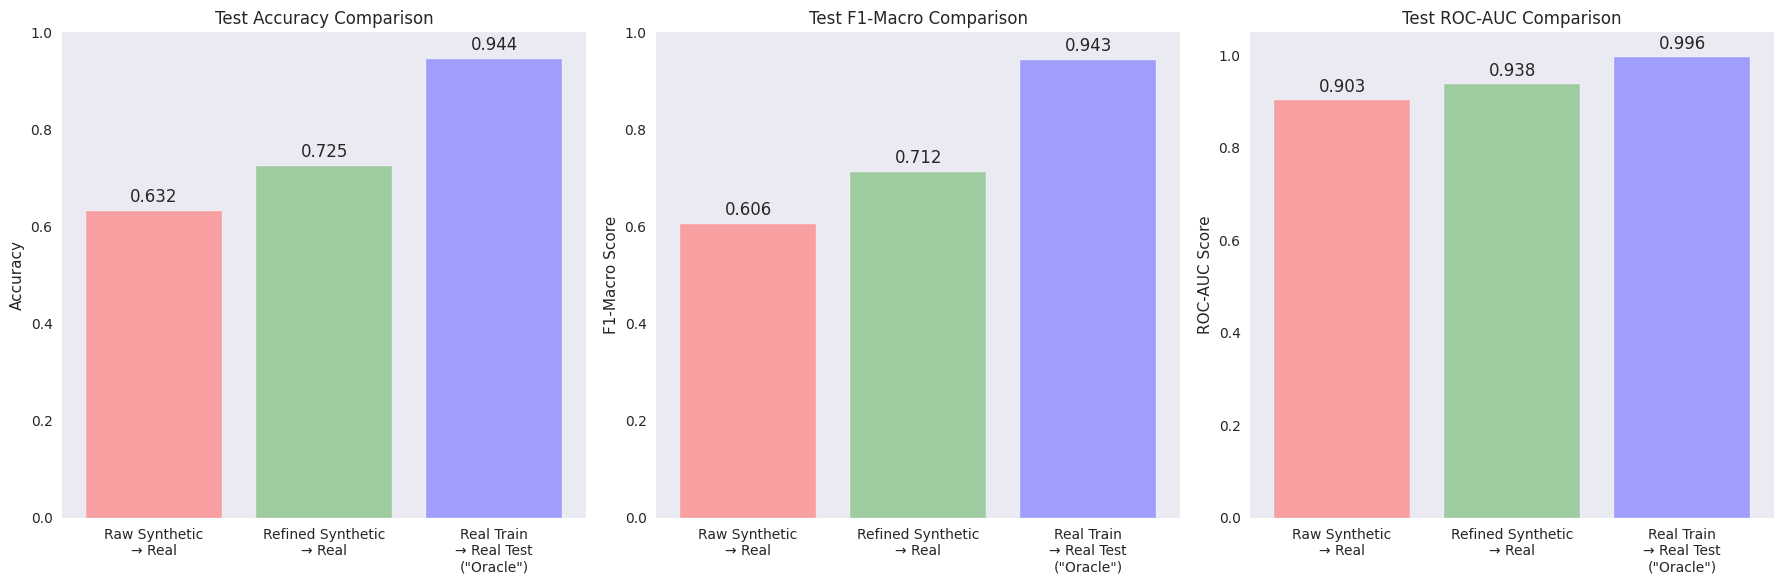

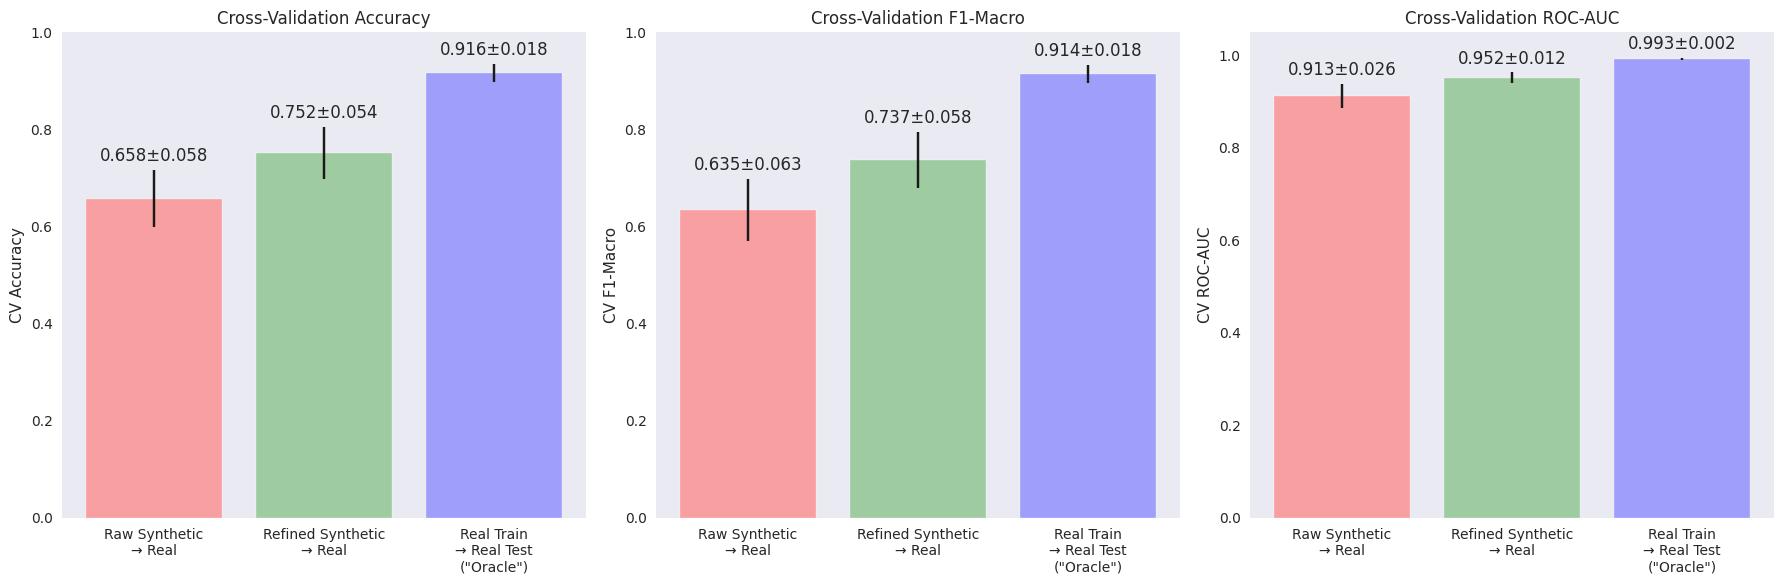


COMPREHENSIVE SUMMARY TABLE
Scenario                       CV Acc       CV F1        CV AUC       Test Acc     Test F1      Test AUC    
------------------------------------------------------------------------------------------------------------------------
Raw Synthetic → Real           0.6576±0.058 0.6346±0.063 0.9133±0.026 0.6320       0.6059       0.9032      
Refined Synthetic → Real       0.7519±0.054 0.7371±0.058 0.9519±0.012 0.7254       0.7122       0.9376      
Real Train → Real Test         0.9160±0.018 0.9142±0.018 0.9930±0.002 0.9444       0.9428       0.9961      

IMPROVEMENT ANALYSIS
Test Accuracy improvement from MAPS refinement: +14.79%
Test F1-Macro improvement from MAPS refinement: +17.54%
CV Accuracy improvement from MAPS refinement: +14.35%

Gap to baseline (Raw Synthetic): 33.08%
Gap to baseline (Refined Synthetic): 23.18%
Refinement reduces gap by: 9.90 percentage points

Note: CV for synthetic scenarios uses 'Train on Synthetic, Validate on Real'
      CV for 

In [22]:
plot_evaluation_results(results, separate_figures=True, figsize=(5,4))
print_summary_table(results)